In [1]:
# Compute PSNR between GT_DIR and PRED_DIR (split each 2x2 stitched image into 4 patches)
import os
import glob
from pathlib import Path

import cv2
import numpy as np

# ===== Paths =====
GT_DIR = "/home/viplab/liukejia/project/result2/render_3d_stitched"
PRED_DIR = "/home/viplab/liukejia/project/result2/inference_images"


def psnr(img1, img2, data_range=255.0):
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10((data_range ** 2) / mse)


def list_images(folder):
    exts = ("*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG")
    files = []
    for ext in exts:
        files.extend(glob.glob(os.path.join(folder, ext)))
    return sorted(files)


def split_2x2(img):
    """Split a 2x2 stitched image into [top-left, top-right, bottom-left, bottom-right]."""
    h, w = img.shape[:2]
    h2, w2 = h // 2, w // 2
    return [
        img[0:h2, 0:w2],
        img[0:h2, w2:w],
        img[h2:h, 0:w2],
        img[h2:h, w2:w],
    ]


if not os.path.isdir(GT_DIR):
    print(f"GT_DIR not found: {GT_DIR}")
elif not os.path.isdir(PRED_DIR):
    print(f"PRED_DIR not found: {PRED_DIR}")
else:
    gt_files = list_images(GT_DIR)
    pred_files = list_images(PRED_DIR)

    print(f"GT images: {len(gt_files)}")
    print(f"PRED images: {len(pred_files)}")

    # First try exact stem matching; otherwise fall back to sorted pairing
    pred_by_stem = {Path(p).stem: p for p in pred_files}
    pairs = []
    unmatched_gt = []

    for g in gt_files:
        stem = Path(g).stem
        if stem in pred_by_stem:
            pairs.append((g, pred_by_stem[stem]))
        else:
            unmatched_gt.append(g)

    if len(pairs) == 0:
        n = min(len(gt_files), len(pred_files))
        pairs = list(zip(gt_files[:n], pred_files[:n]))
        print("No same-name files found, falling back to sorted pairing.")
    elif len(unmatched_gt) > 0:
        print(f"{len(unmatched_gt)} GT images did not find matching PRED files and will be ignored.")

    patch_psnr_values = []
    image_avg_records = []
    skipped_images = 0

    for gt_path, pred_path in pairs:
        gt_bgr = cv2.imread(gt_path, cv2.IMREAD_COLOR)
        pred_bgr = cv2.imread(pred_path, cv2.IMREAD_COLOR)
        if gt_bgr is None or pred_bgr is None:
            skipped_images += 1
            continue

        gt_rgb = cv2.cvtColor(gt_bgr, cv2.COLOR_BGR2RGB)
        pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)

        cur_vals = []
        for gt_patch, pred_patch in zip(gt_patches, pred_patches):
            if pred_patch.shape[:2] != gt_patch.shape[:2]:
                pred_patch = cv2.resize(
                    pred_patch,
                    (gt_patch.shape[1], gt_patch.shape[0]),
                    interpolation=cv2.INTER_AREA,
                )
            v = psnr(gt_patch, pred_patch, data_range=255.0)
            patch_psnr_values.append(v)
            cur_vals.append(v)

        image_avg_records.append((Path(gt_path).name, float(np.mean(cur_vals))))

    if len(patch_psnr_values) == 0:
        print("No valid samples found. Please check image readability and pairing rules.")
    else:
        vals = np.array(patch_psnr_values, dtype=np.float64)
        expected = 9 * 4
        print(f"Paired full images: {len(image_avg_records)}, skipped full images: {skipped_images}")
        print(f"Patch PSNR samples: {len(vals)} (should be {expected} if all 9 images are valid)")
        print(f"Mean PSNR: {vals.mean():.4f} dB")
        print(f"Median PSNR: {np.median(vals):.4f} dB")
        print(f"Min PSNR: {vals.min():.4f} dB")
        print(f"Max PSNR: {vals.max():.4f} dB")
        print(f"Std PSNR: {vals.std():.4f} dB")

        print("\nFirst 5 images (4-patch mean PSNR):")
        for name, v in image_avg_records[:5]:
            print(f"  {name}: {v:.4f} dB")

GT images: 105
PRED images: 114
Paired full images: 105, skipped full images: 0
Patch PSNR samples: 420 (should be 36 if all 9 images are valid)
Mean PSNR: 14.2710 dB
Median PSNR: 14.3036 dB
Min PSNR: 10.3135 dB
Max PSNR: 18.7441 dB
Std PSNR: 1.1544 dB

First 5 images (4-patch mean PSNR):
  num123_-1000_0_0_0064.png: 13.5640 dB
  num123_-1000_100_0_0066.png: 14.4504 dB
  num123_-1000_150_0_0067.png: 14.2166 dB
  num123_-1000_200_0_0068.png: 13.5434 dB
  num123_-1000_250_0_0069.png: 13.5085 dB


In [2]:
# Recompute PSNR after histogram equalization to reduce color-scale mismatch
import cv2
import numpy as np


def equalize_luminance(img_rgb):
    """Apply histogram equalization on the luminance channel (Y) in YCrCb space."""
    ycrcb = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
    y, cr, cb = cv2.split(ycrcb)
    y_eq = cv2.equalizeHist(y)
    eq = cv2.merge([y_eq, cr, cb])
    return cv2.cvtColor(eq, cv2.COLOR_YCrCb2RGB)


if 'pairs' not in globals() or len(pairs) == 0:
    print('Please run the previous cell first so that image pairs are prepared.')
else:
    eq_patch_psnr_values = []
    eq_image_avg_records = []
    eq_skipped_images = 0

    for gt_path, pred_path in pairs:
        gt_bgr = cv2.imread(gt_path, cv2.IMREAD_COLOR)
        pred_bgr = cv2.imread(pred_path, cv2.IMREAD_COLOR)
        if gt_bgr is None or pred_bgr is None:
            eq_skipped_images += 1
            continue

        gt_rgb = cv2.cvtColor(gt_bgr, cv2.COLOR_BGR2RGB)
        pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)

        cur_vals = []
        for gt_patch, pred_patch in zip(gt_patches, pred_patches):
            if pred_patch.shape[:2] != gt_patch.shape[:2]:
                pred_patch = cv2.resize(
                    pred_patch,
                    (gt_patch.shape[1], gt_patch.shape[0]),
                    interpolation=cv2.INTER_AREA,
                )

            gt_eq = equalize_luminance(gt_patch)
            pred_eq = equalize_luminance(pred_patch)

            v = psnr(gt_eq, pred_eq, data_range=255.0)
            eq_patch_psnr_values.append(v)
            cur_vals.append(v)

        eq_image_avg_records.append((Path(gt_path).name, float(np.mean(cur_vals))))

    if len(eq_patch_psnr_values) == 0:
        print('No valid samples found after histogram equalization.')
    else:
        vals = np.array(eq_patch_psnr_values, dtype=np.float64)
        print(f'Paired full images: {len(eq_image_avg_records)}, skipped full images: {eq_skipped_images}')
        print(f'Patch PSNR samples after equalization: {len(vals)}')
        print(f'Mean PSNR after equalization: {vals.mean():.4f} dB')
        print(f'Median PSNR after equalization: {np.median(vals):.4f} dB')
        print(f'Min PSNR after equalization: {vals.min():.4f} dB')
        print(f'Max PSNR after equalization: {vals.max():.4f} dB')
        print(f'Std PSNR after equalization: {vals.std():.4f} dB')

        print('\nFirst 5 images after equalization (4-patch mean PSNR):')
        for name, v in eq_image_avg_records[:5]:
            print(f'  {name}: {v:.4f} dB')

Paired full images: 105, skipped full images: 0
Patch PSNR samples after equalization: 420
Mean PSNR after equalization: 12.8459 dB
Median PSNR after equalization: 12.9122 dB
Min PSNR after equalization: 8.7613 dB
Max PSNR after equalization: 15.8902 dB
Std PSNR after equalization: 1.3483 dB

First 5 images after equalization (4-patch mean PSNR):
  num123_-1000_0_0_0064.png: 12.6241 dB
  num123_-1000_100_0_0066.png: 13.3304 dB
  num123_-1000_150_0_0067.png: 13.4152 dB
  num123_-1000_200_0_0068.png: 12.8453 dB
  num123_-1000_250_0_0069.png: 10.8187 dB


Worst sample before equalization: num123_-1450_300_0_0007.png | PSNR = 11.2275 dB
Worst sample after equalization:  num123_-1450_200_0_0005.png | PSNR = 8.9629 dB

=== Worst sample before equalization ===


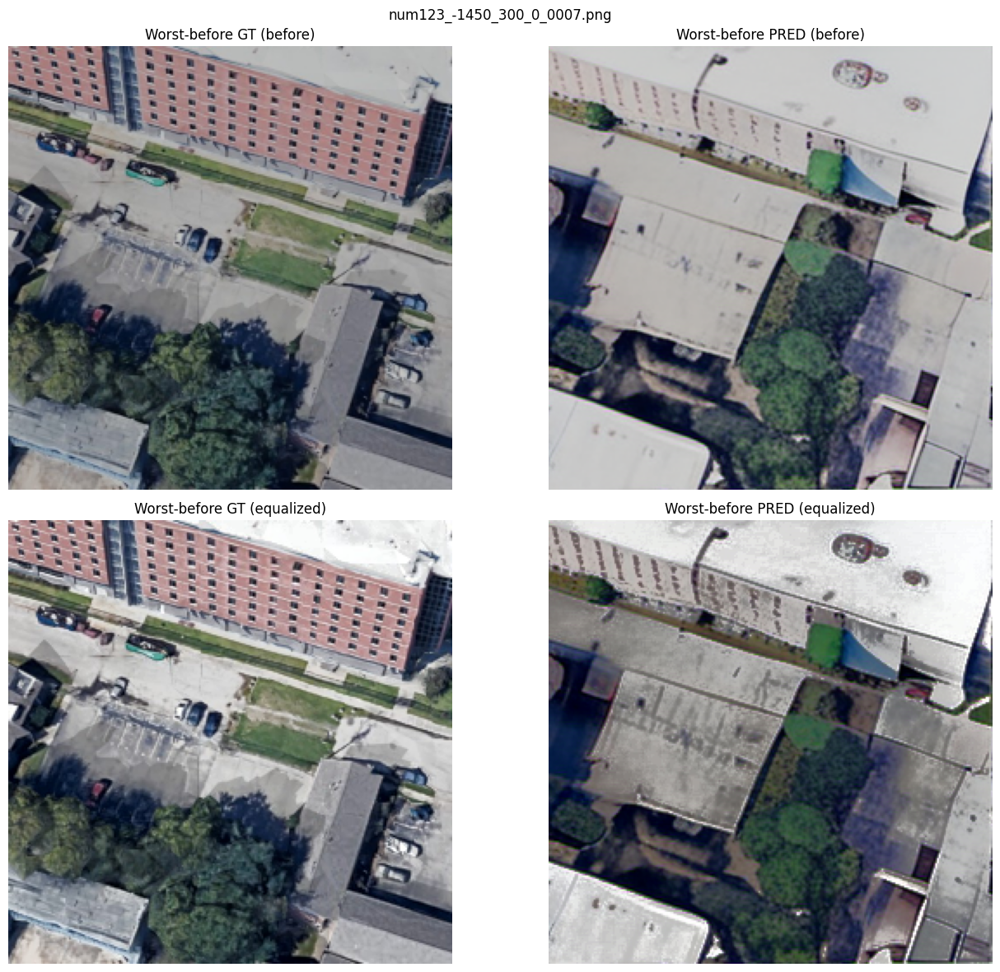


=== Worst sample after equalization ===


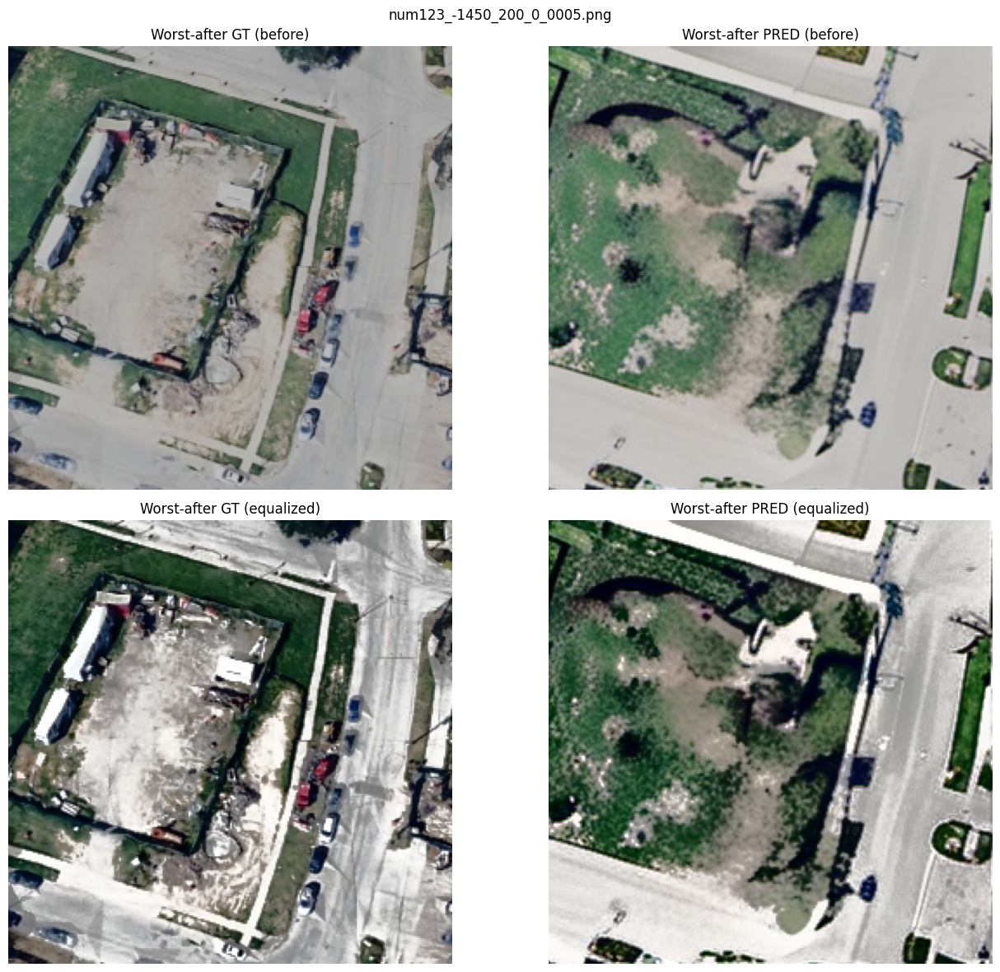

In [3]:
# Show the worst sample before and after histogram equalization
import matplotlib.pyplot as plt


def load_rgb(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


if 'pairs' not in globals() or len(pairs) == 0:
    print('Please run the previous cells first so that image pairs are prepared.')
elif 'image_avg_records' not in globals() or 'eq_image_avg_records' not in globals():
    print('Please run both PSNR cells first so that before/after statistics are available.')
else:
    # Worst sample before equalization
    worst_before_name, worst_before_psnr = min(image_avg_records, key=lambda x: x[1])
    # Worst sample after equalization
    worst_after_name, worst_after_psnr = min(eq_image_avg_records, key=lambda x: x[1])

    print(f'Worst sample before equalization: {worst_before_name} | PSNR = {worst_before_psnr:.4f} dB')
    print(f'Worst sample after equalization:  {worst_after_name} | PSNR = {worst_after_psnr:.4f} dB')

    name_to_pair = {Path(g).name: (g, p) for g, p in pairs}

    def show_pair(sample_name, title_prefix):
        if sample_name not in name_to_pair:
            print(f'Sample not found in current pairs: {sample_name}')
            return

        gt_path, pred_path = name_to_pair[sample_name]
        gt_rgb = load_rgb(gt_path)
        pred_rgb = load_rgb(pred_path)
        if gt_rgb is None or pred_rgb is None:
            print(f'Failed to read image pair: {sample_name}')
            return

        gt_eq = equalize_luminance(gt_rgb)
        pred_eq = equalize_luminance(pred_rgb)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)
        gt_eq_patches = split_2x2(gt_eq)
        pred_eq_patches = split_2x2(pred_eq)

        fig, axes = plt.subplots(2, 2, figsize=(14, 12))
        axes[0, 0].imshow(gt_patches[0])
        axes[0, 0].set_title(f'{title_prefix} GT (before)')
        axes[0, 0].axis('off')

        axes[0, 1].imshow(pred_patches[0])
        axes[0, 1].set_title(f'{title_prefix} PRED (before)')
        axes[0, 1].axis('off')
        

        axes[1, 0].imshow(gt_eq_patches[0])
        axes[1, 0].set_title(f'{title_prefix} GT (equalized)')
        axes[1, 0].axis('off')

        axes[1, 1].imshow(pred_eq_patches[0])
        axes[1, 1].set_title(f'{title_prefix} PRED (equalized)')
        axes[1, 1].axis('off')

        fig.suptitle(sample_name)
        plt.tight_layout()
        plt.show()

    # Show the worst case before equalization and the worst case after equalization
    print('\n=== Worst sample before equalization ===')
    show_pair(worst_before_name, 'Worst-before')

    print('\n=== Worst sample after equalization ===')
    if worst_after_name != worst_before_name:
        show_pair(worst_after_name, 'Worst-after')
    else:
        print('The same sample is worst both before and after equalization.')

In [4]:
# Compute SSIM and LPIPS for patches (before and after histogram equalization)
import numpy as np

# Try SSIM
try:
    from skimage.metrics import structural_similarity as ssim_fn
    HAS_SSIM = True
except Exception as e:
    HAS_SSIM = False
    _ssim_err = e

# Try LPIPS
try:
    import torch
    import lpips
    HAS_LPIPS = True
except Exception as e:
    HAS_LPIPS = False
    _lpips_err = e

if 'pairs' not in globals() or len(pairs) == 0:
    print('Please run the pairing cell first (prepare `pairs`).')
else:
    ssim_patch_vals = []
    ssim_image_records = []
    eq_ssim_patch_vals = []
    eq_ssim_image_records = []

    lpips_patch_vals = []
    lpips_image_records = []
    eq_lpips_patch_vals = []
    eq_lpips_image_records = []

    if HAS_LPIPS:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        lpips_model = lpips.LPIPS(net='alex').to(device)

    skipped = 0
    for gt_path, pred_path in pairs:
        gt_bgr = cv2.imread(gt_path, cv2.IMREAD_COLOR)
        pred_bgr = cv2.imread(pred_path, cv2.IMREAD_COLOR)
        if gt_bgr is None or pred_bgr is None:
            skipped += 1
            continue

        gt_rgb = cv2.cvtColor(gt_bgr, cv2.COLOR_BGR2RGB)
        pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)

        gt_patches = split_2x2(gt_rgb)
        pred_patches = split_2x2(pred_rgb)

        cur_ssim = []
        cur_eq_ssim = []
        cur_lpips = []
        cur_eq_lpips = []

        for g, p in zip(gt_patches, pred_patches):
            if p.shape[:2] != g.shape[:2]:
                p = cv2.resize(p, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_AREA)

            # SSIM (before)
            if HAS_SSIM:
                v = ssim_fn(g, p, channel_axis=2, data_range=255)
                ssim_patch_vals.append(float(v))
                cur_ssim.append(float(v))

            # LPIPS (before)
            if HAS_LPIPS:
                g_t = torch.from_numpy(((g.astype(np.float32) / 255.0) * 2.0 - 1.0).transpose(2, 0, 1)).unsqueeze(0).to(device)
                p_t = torch.from_numpy(((p.astype(np.float32) / 255.0) * 2.0 - 1.0).transpose(2, 0, 1)).unsqueeze(0).to(device)
                with torch.no_grad():
                    val = lpips_model(g_t, p_t)
                v_lp = float(val.cpu().item())
                lpips_patch_vals.append(v_lp)
                cur_lpips.append(v_lp)

            # Equalized versions
            g_eq = equalize_luminance(g)
            p_eq = equalize_luminance(p)

            if HAS_SSIM:
                v2 = ssim_fn(g_eq, p_eq, channel_axis=2, data_range=255)
                eq_ssim_patch_vals.append(float(v2))
                cur_eq_ssim.append(float(v2))

            if HAS_LPIPS:
                gte = torch.from_numpy(((g_eq.astype(np.float32) / 255.0) * 2.0 - 1.0).transpose(2, 0, 1)).unsqueeze(0).to(device)
                pte = torch.from_numpy(((p_eq.astype(np.float32) / 255.0) * 2.0 - 1.0).transpose(2, 0, 1)).unsqueeze(0).to(device)
                with torch.no_grad():
                    val2 = lpips_model(gte, pte)
                v_lp2 = float(val2.cpu().item())
                eq_lpips_patch_vals.append(v_lp2)
                cur_eq_lpips.append(v_lp2)

        if HAS_SSIM and len(cur_ssim) > 0:
            ssim_image_records.append((Path(gt_path).name, float(np.mean(cur_ssim))))
        if HAS_SSIM and len(cur_eq_ssim) > 0:
            eq_ssim_image_records.append((Path(gt_path).name, float(np.mean(cur_eq_ssim))))
        if HAS_LPIPS and len(cur_lpips) > 0:
            lpips_image_records.append((Path(gt_path).name, float(np.mean(cur_lpips))))
        if HAS_LPIPS and len(cur_eq_lpips) > 0:
            eq_lpips_image_records.append((Path(gt_path).name, float(np.mean(cur_eq_lpips))))

    print(f"Processed pairs: {len(pairs)}, skipped: {skipped}")

    # Print SSIM summary
    if HAS_SSIM:
        arr = np.array(ssim_patch_vals, dtype=np.float64)
        eq_arr = np.array(eq_ssim_patch_vals, dtype=np.float64)
        print('\n[SSIM]')
        if arr.size > 0:
            print(f'  patches count: {arr.size}')
            print(f'  mean: {arr.mean():.6f}, median: {np.median(arr):.6f}, min: {arr.min():.6f}, max: {arr.max():.6f}, std: {arr.std():.6f}')
        else:
            print('  no SSIM patch values computed')
        if eq_arr.size > 0:
            print(f'  (after equalization) mean: {eq_arr.mean():.6f}, median: {np.median(eq_arr):.6f}, min: {eq_arr.min():.6f}, max: {eq_arr.max():.6f}, std: {eq_arr.std():.6f}')

    else:
        print('\n[SSIM] skimage not available:', _ssim_err)

    # Print LPIPS summary
    if HAS_LPIPS:
        arr_lp = np.array(lpips_patch_vals, dtype=np.float64)
        eq_arr_lp = np.array(eq_lpips_patch_vals, dtype=np.float64)
        print('\n[LPIPS]')
        if arr_lp.size > 0:
            print(f'  patches count: {arr_lp.size}')
            print(f'  mean: {arr_lp.mean():.6f}, median: {np.median(arr_lp):.6f}, min: {arr_lp.min():.6f}, max: {arr_lp.max():.6f}, std: {arr_lp.std():.6f}')
        else:
            print('  no LPIPS patch values computed')
        if eq_arr_lp.size > 0:
            print(f'  (after equalization) mean: {eq_arr_lp.mean():.6f}, median: {np.median(eq_arr_lp):.6f}, min: {eq_arr_lp.min():.6f}, max: {eq_arr_lp.max():.6f}, std: {eq_arr_lp.std():.6f}')
    else:
        print('\n[LPIPS] lpips not available:', _lpips_err)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth
Processed pairs: 105, skipped: 0

[SSIM]
  patches count: 420
  mean: 0.330563, median: 0.331054, min: 0.135312, max: 0.540800, std: 0.077040
  (after equalization) mean: 0.225891, median: 0.230249, min: 0.049656, max: 0.362677, std: 0.058601

[LPIPS]
  patches count: 420
  mean: 0.298204, median: 0.283802, min: 0.210247, max: 0.529343, std: 0.062881
  (after equalization) mean: 0.309682, median: 0.300533, min: 0.197060, max: 0.534483, std: 0.060243


Worst SSIM before equalization: num123_-1450_100_0_0003.png (SSIM=0.145738)


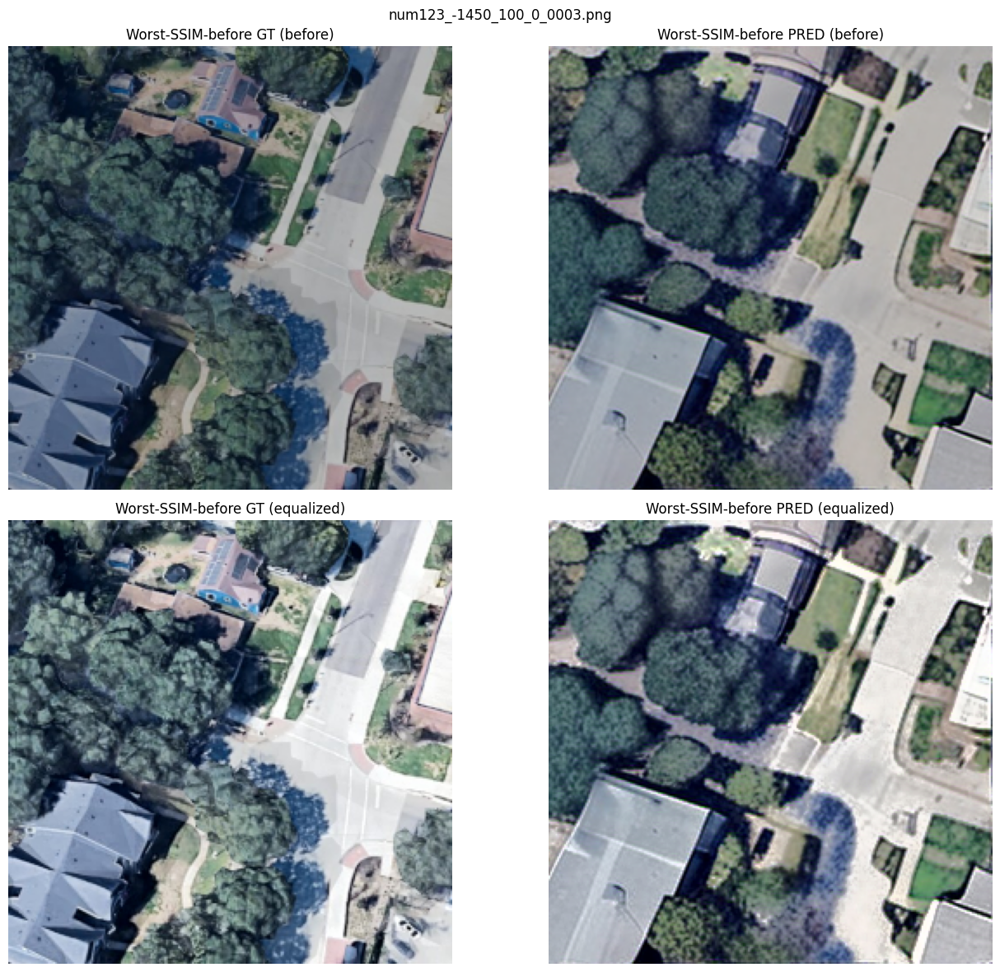

Worst SSIM after equalization: num123_-1450_200_0_0005.png (SSIM=0.060109)


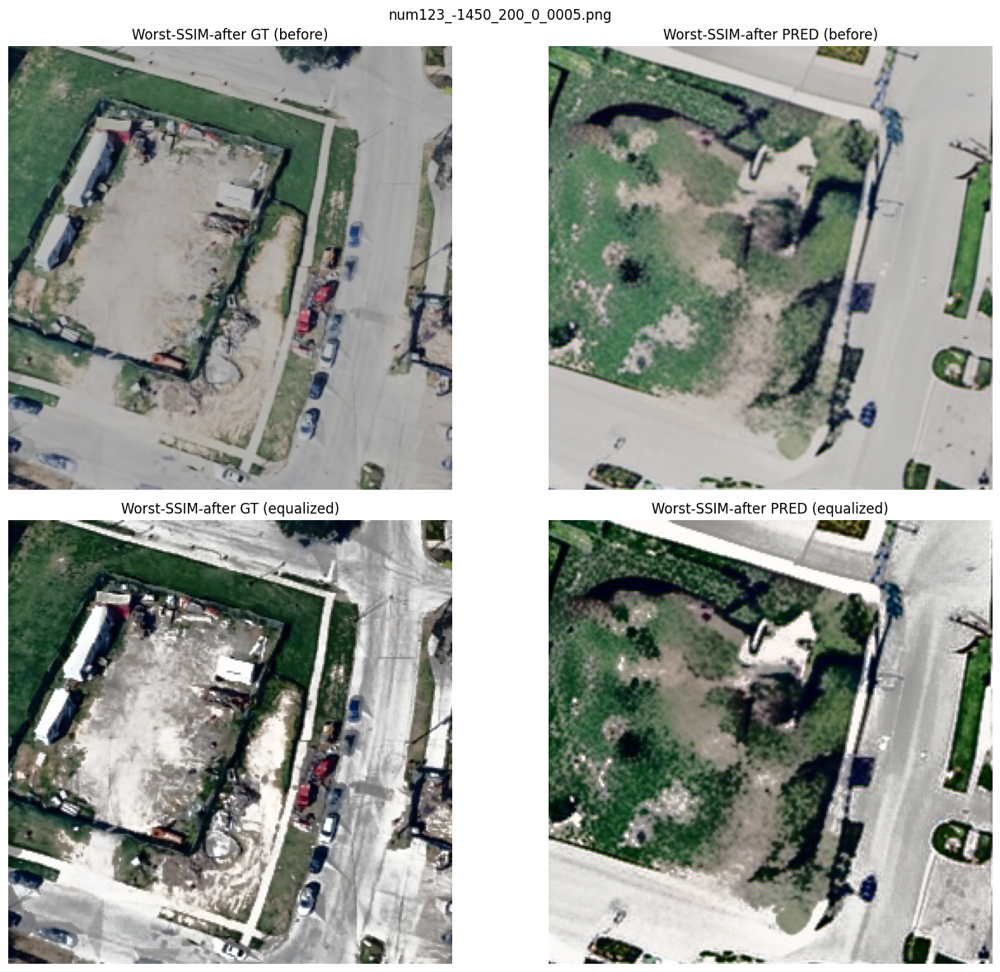

Worst LPIPS before equalization: num123_-1450_300_0_0007.png (LPIPS=0.522907)


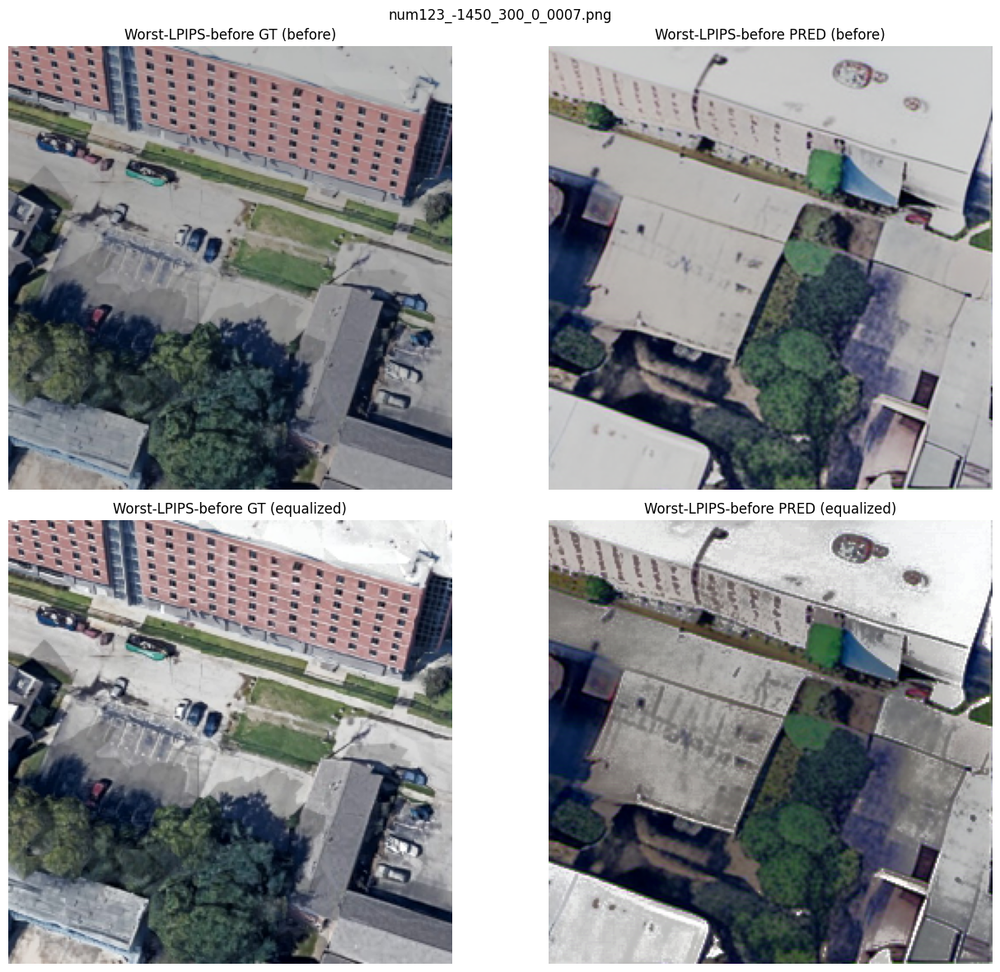

Worst LPIPS after equalization: num123_-1450_200_0_0005.png (LPIPS=0.522384)


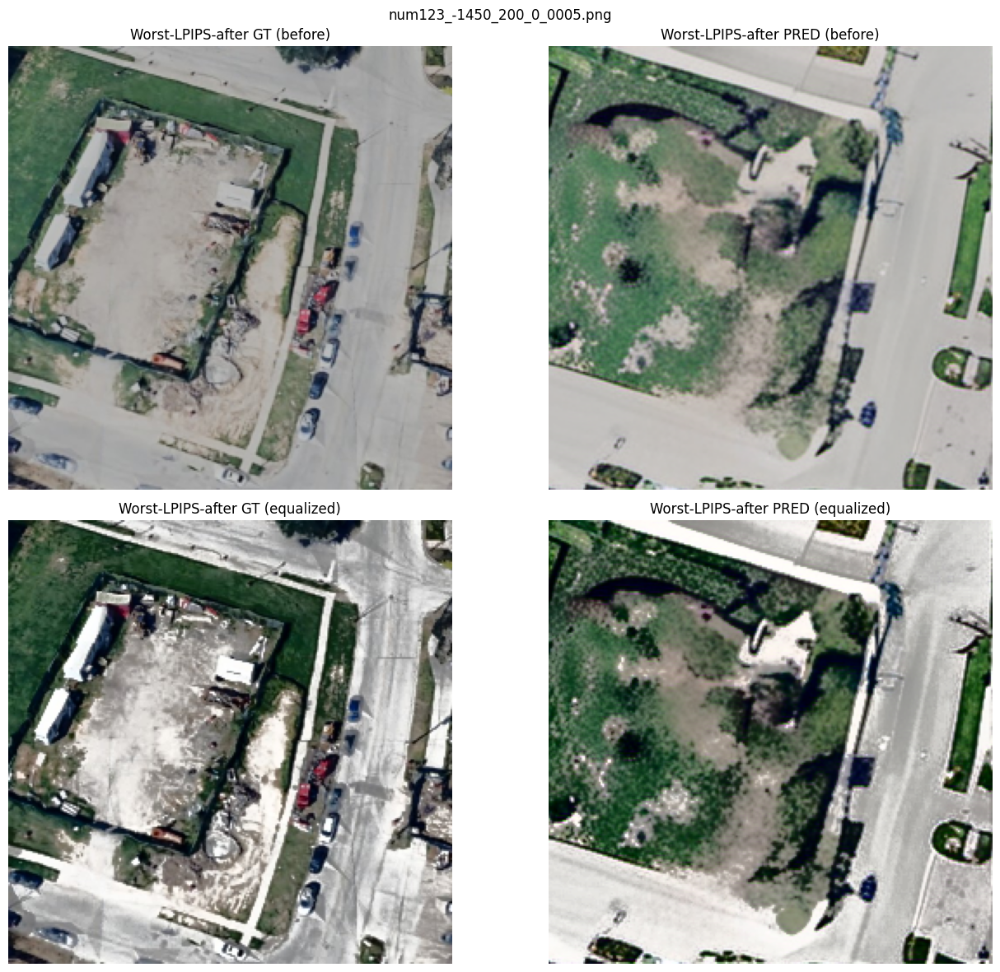

In [5]:
# Display worst samples for SSIM and LPIPS (before and after equalization)
import matplotlib.pyplot as plt


def show_pair_for_metric(sample_name, title_prefix):
    if sample_name not in name_to_pair:
        print(f'Sample not found: {sample_name}')
        return
    gt_path, pred_path = name_to_pair[sample_name]
    gt_rgb = load_rgb(gt_path)
    pred_rgb = load_rgb(pred_path)
    if gt_rgb is None or pred_rgb is None:
        print(f'Failed to read images for {sample_name}')
        return

    gt_eq = equalize_luminance(gt_rgb)
    pred_eq = equalize_luminance(pred_rgb)

    gt_patches = split_2x2(gt_rgb)
    pred_patches = split_2x2(pred_rgb)
    gt_eq_patches = split_2x2(gt_eq)
    pred_eq_patches = split_2x2(pred_eq)

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes[0, 0].imshow(gt_patches[0])
    axes[0, 0].set_title(f'{title_prefix} GT (before)')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(pred_patches[0])
    axes[0, 1].set_title(f'{title_prefix} PRED (before)')
    axes[0, 1].axis('off')

    axes[1, 0].imshow(gt_eq_patches[0])
    axes[1, 0].set_title(f'{title_prefix} GT (equalized)')
    axes[1, 0].axis('off')

    axes[1, 1].imshow(pred_eq_patches[0])
    axes[1, 1].set_title(f'{title_prefix} PRED (equalized)')
    axes[1, 1].axis('off')

    fig.suptitle(sample_name)
    plt.tight_layout()
    plt.show()

# Require computed records
if 'ssim_image_records' not in globals() and 'lpips_image_records' not in globals():
    print('Please run the SSIM/LPIPS computation cell first.')
else:
    # SSIM worst (min)
    if HAS_SSIM and len(ssim_image_records) > 0:
        worst_ssim_name, worst_ssim_val = min(ssim_image_records, key=lambda x: x[1])
        worst_eq_ssim_name, worst_eq_ssim_val = min(eq_ssim_image_records, key=lambda x: x[1])
        print(f'Worst SSIM before equalization: {worst_ssim_name} (SSIM={worst_ssim_val:.6f})')
        show_pair_for_metric(worst_ssim_name, 'Worst-SSIM-before')
        print(f'Worst SSIM after equalization: {worst_eq_ssim_name} (SSIM={worst_eq_ssim_val:.6f})')
        if worst_eq_ssim_name != worst_ssim_name:
            show_pair_for_metric(worst_eq_ssim_name, 'Worst-SSIM-after')
    else:
        print('SSIM not computed or unavailable.')

    # LPIPS worst (max)
    if HAS_LPIPS and len(lpips_image_records) > 0:
        worst_lpips_name, worst_lpips_val = max(lpips_image_records, key=lambda x: x[1])
        worst_eq_lpips_name, worst_eq_lpips_val = max(eq_lpips_image_records, key=lambda x: x[1])
        print(f'Worst LPIPS before equalization: {worst_lpips_name} (LPIPS={worst_lpips_val:.6f})')
        show_pair_for_metric(worst_lpips_name, 'Worst-LPIPS-before')
        print(f'Worst LPIPS after equalization: {worst_eq_lpips_name} (LPIPS={worst_eq_lpips_val:.6f})')
        if worst_eq_lpips_name != worst_lpips_name:
            show_pair_for_metric(worst_eq_lpips_name, 'Worst-LPIPS-after')
    else:
        print('LPIPS not computed or unavailable.')

In [9]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
import lpips
import torch

# ===== Paths =====
GT_DIR = "/home/viplab/liukejia/project/result2/render_3d_stitched"
PRED_DIR = "/home/viplab/liukejia/project/result2/inference_images"
OUTPUT_DIR = "/home/viplab/liukejia/project/result2/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ===== LPIPS model =====
lpips_fn = lpips.LPIPS(net='alex').cuda()

def load_image_pair(gt_path, pred_path, size=(256, 256)):
    gt = Image.open(gt_path).convert('RGB').resize(size)
    pred = Image.open(pred_path).convert('RGB').resize(size)
    return np.array(gt), np.array(pred)

# ===== Scan for matching pairs =====
gt_files = sorted([f for f in os.listdir(GT_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
pred_files = sorted([f for f in os.listdir(PRED_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
common_files = list(set(gt_files) & set(pred_files))
print(f"Found {len(common_files)} matched pairs")

# ===== Compute metrics for all pairs =====
results = []
for fname in common_files:
    gt_path = os.path.join(GT_DIR, fname)
    pred_path = os.path.join(PRED_DIR, fname)
    gt_img, pred_img = load_image_pair(gt_path, pred_path)

    # PSNR
    p = psnr(gt_img, pred_img, data_range=255)
    # SSIM (average over channels)
    s = ssim(gt_img, pred_img, data_range=255, channel_axis=2)
    # LPIPS
    gt_tensor = torch.from_numpy(gt_img).permute(2, 0, 1).unsqueeze(0).float().cuda() / 255.0 * 2 - 1
    pred_tensor = torch.from_numpy(pred_img).permute(2, 0, 1).unsqueeze(0).float().cuda() / 255.0 * 2 - 1
    with torch.no_grad():
        l = lpips_fn(gt_tensor, pred_tensor).item()

    results.append({
        'fname': fname,
        'psnr': p,
        'ssim': s,
        'lpips': l,
        'gt_path': gt_path,
        'pred_path': pred_path
    })

# Sort by PSNR ascending (worst first)
results.sort(key=lambda x: x['psnr'])

# ============================================================
# Figure 4: Overview (median quality, 16 pairs, 4x4 grid)
# ============================================================
N_OVERVIEW = 16
median_start = len(results) // 2 - N_OVERVIEW // 2
overview_samples = results[median_start:median_start + N_OVERVIEW]

print("\n===== Figure 4: Overview samples =====")
for i, s in enumerate(overview_samples):
    print(f"{i+1}: {s['fname']} (PSNR: {s['psnr']:.2f}, SSIM: {s['ssim']:.3f}, LPIPS: {s['lpips']:.3f})")

fig4, axes = plt.subplots(4, 4, figsize=(16, 14))
axes_flat = axes.flatten()

for idx, sample in enumerate(overview_samples):
    gt_img, pred_img = load_image_pair(sample['gt_path'], sample['pred_path'])
    combined = np.hstack([gt_img, pred_img])
    ax = axes_flat[idx]
    ax.imshow(combined)
    ax.axis('off')

    title = f"PSNR: {sample['psnr']:.1f} | SSIM: {sample['ssim']:.3f} | LPIPS: {sample['lpips']:.3f}"
    ax.set_title(title, fontsize=7)

    ax.text(0.47, 0.95, 'GT', transform=ax.transAxes,
            fontsize=7, color='white', ha='right', va='top',
            bbox=dict(facecolor='black', alpha=0.5, pad=0.5))
    ax.text(0.97, 0.95, 'Predicted', transform=ax.transAxes,
            fontsize=7, color='white', ha='right', va='top',
            bbox=dict(facecolor='black', alpha=0.5, pad=0.5))

for idx in range(N_OVERVIEW, len(axes_flat)):
    axes_flat[idx].axis('off')

plt.tight_layout()
fig4.savefig(os.path.join(OUTPUT_DIR, 'fig4_overview.png'), dpi=200, bbox_inches='tight')
plt.close()
print(f"Figure 4 saved to {os.path.join(OUTPUT_DIR, 'fig4_overview.png')}")

# ============================================================
# Figure 5: Challenging cases (worst by each metric, up to 6 pairs)
# ============================================================
N_CHALLENGE = 6
worst_psnr = sorted(results, key=lambda x: x['psnr'])[:2]
worst_ssim = sorted(results, key=lambda x: x['ssim'])[:2]
worst_lpips = sorted(results, key=lambda x: x['lpips'], reverse=True)[:2]

seen = set()
challenge_samples = []
for sample in worst_psnr + worst_ssim + worst_lpips:
    if sample['fname'] not in seen:
        seen.add(sample['fname'])
        challenge_samples.append(sample)
    if len(challenge_samples) >= N_CHALLENGE:
        break

print("\n===== Figure 5: Challenge samples =====")
for i, s in enumerate(challenge_samples):
    print(f"{i+1}: {s['fname']} (PSNR: {s['psnr']:.2f}, SSIM: {s['ssim']:.3f}, LPIPS: {s['lpips']:.3f})")

n_cols = len(challenge_samples)
fig5, axes5 = plt.subplots(1, n_cols, figsize=(4 * n_cols, 5))
if n_cols == 1:
    axes5 = [axes5]

for idx, sample in enumerate(challenge_samples):
    gt_img, pred_img = load_image_pair(sample['gt_path'], sample['pred_path'])
    combined = np.hstack([gt_img, pred_img])
    ax = axes5[idx]
    ax.imshow(combined)
    ax.axis('off')

    title = f"PSNR: {sample['psnr']:.1f} | SSIM: {sample['ssim']:.3f} | LPIPS: {sample['lpips']:.3f}"
    ax.set_title(title, fontsize=7)

    ax.text(0.47, 0.95, 'GT', transform=ax.transAxes,
            fontsize=7, color='white', ha='right', va='top',
            bbox=dict(facecolor='black', alpha=0.5, pad=0.5))
    ax.text(0.97, 0.95, 'Predicted', transform=ax.transAxes,
            fontsize=7, color='white', ha='right', va='top',
            bbox=dict(facecolor='black', alpha=0.5, pad=0.5))

plt.tight_layout()
fig5.savefig(os.path.join(OUTPUT_DIR, 'fig5_challenge.png'), dpi=200, bbox_inches='tight')
plt.close()
print(f"Figure 5 saved to {os.path.join(OUTPUT_DIR, 'fig5_challenge.png')}")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: /home/viplab/anaconda3/envs/cnet2/lib/python3.10/site-packages/lpips/weights/v0.1/alex.pth
Found 105 matched pairs

===== Figure 4: Overview samples =====
1: num123_-950_150_0_0074.png (PSNR: 14.76, SSIM: 0.414, LPIPS: 0.260)
2: num123_-1250_50_0_0030.png (PSNR: 14.78, SSIM: 0.399, LPIPS: 0.265)
3: num123_-800_150_0_0095.png (PSNR: 14.83, SSIM: 0.461, LPIPS: 0.208)
4: num123_-1050_200_0_0061.png (PSNR: 14.89, SSIM: 0.421, LPIPS: 0.182)
5: num123_-1150_300_0_0049.png (PSNR: 14.92, SSIM: 0.374, LPIPS: 0.230)
6: num123_-1000_150_0_0067.png (PSNR: 14.93, SSIM: 0.399, LPIPS: 0.285)
7: num123_-850_0_0_0085.png (PSNR: 14.93, SSIM: 0.398, LPIPS: 0.233)
8: num123_-1200_200_0_0040.png (PSNR: 14.95, SSIM: 0.422, LPIPS: 0.253)
9: num123_-1050_0_0_0057.png (PSNR: 14.96, SSIM: 0.369, LPIPS: 0.260)
10: num123_-950_100_0_0073.png (PSNR: 14.97, SSIM: 0.469, LPIPS: 0.181)
11: num123_-900_100_0_0080.png (PSNR: 15.